In [63]:
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

print("Matplotlib:", matplotlib.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

Matplotlib: 3.10.0
NumPy: 2.4.6
Pandas: 2.2.3


1.1 Understanding Matplotlib, Figure, and Axes

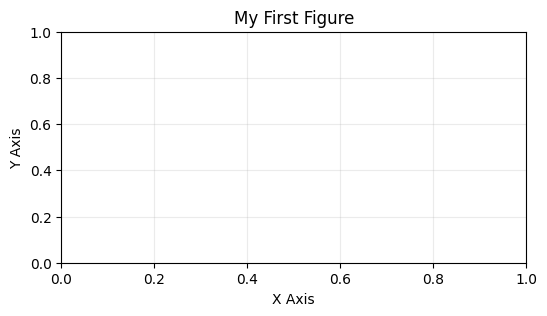

In [64]:
fig, ax = plt.subplots(figsize=(6, 3))
ax.set_title("My First Figure")
ax.set_xlabel("X Axis")
ax.set_ylabel("Y Axis")
ax.grid(alpha=0.25)
plt.show()


1.2 Creating a Simple Line Plot

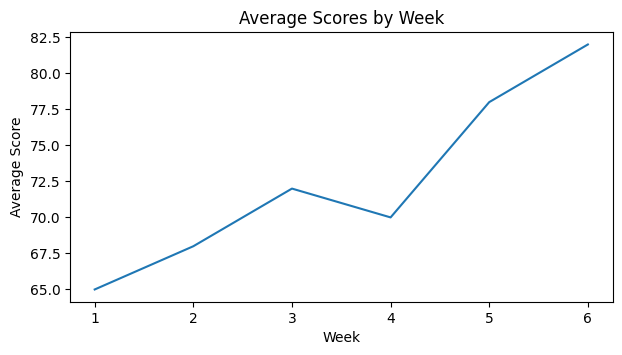

In [65]:
weeks = np.array([1, 2, 3, 4, 5, 6])
average_scores = np.array([65, 68, 72, 70, 78, 82])

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(weeks, average_scores)
ax.set_title("Average Scores by Week")
ax.set_xlabel("Week")
ax.set_ylabel("Average Score")
ax.set_xticks(weeks)
plt.show()

1.3 Customizing Lines, Markers, and Labels

In [66]:
class_a = np.array([65, 68, 72, 70, 78, 82])
class_b = np.array([62, 66, 67, 73, 75, 79])


1.4 Creating Multiple Subplots

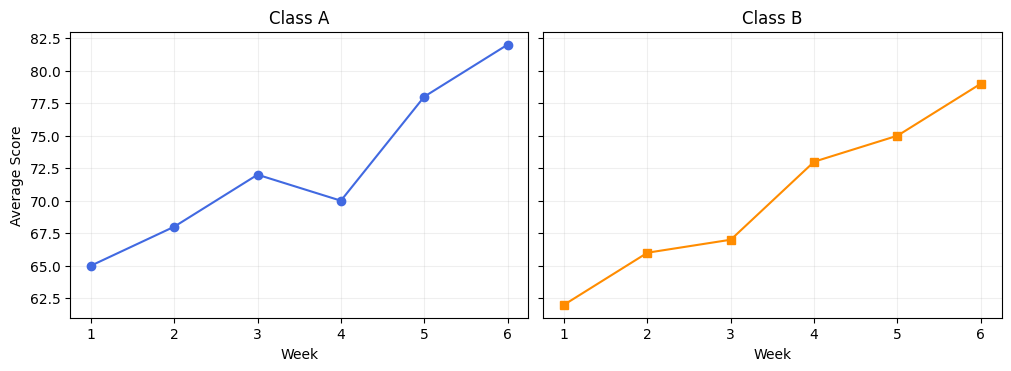

In [67]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True, layout="constrained")
axes[0].plot(weeks, class_a, marker="o", color="royalblue")
axes[0].set(title="Class A", xlabel="Week", ylabel="Average Score")

axes[1].plot(weeks, class_b, marker="s", color="darkorange")
axes[1].set(title="Class B", xlabel="Week")
for ax in axes:
    ax.set_xticks(weeks)
    ax.grid(alpha=0.2)
plt.show()

2.1 Preparing Dates and Observations

In [68]:
dates = pd.date_range(start="2026-01-01", periods=12, freq="MS")
rainfall = np.array([245, 218, 230, 275, 310, 185, 145, 125, 165, 235, 290, 265])
temperature = np.array([27.5, 27.8, 28.0, 28.2, 28.1, 28.6, 28.8, 29.0, 28.9, 28.4, 28.0, 27.7])
# dates menjadi index
weather = pd.DataFrame({"Rainfall_mm": rainfall, "Temperature_C": temperature}, index=dates)
weather.index.name = "Date"

print("\nIndex type:", type(weather.index).__name__)
print(weather)


Index type: DatetimeIndex
            Rainfall_mm  Temperature_C
Date                                  
2026-01-01          245           27.5
2026-02-01          218           27.8
2026-03-01          230           28.0
2026-04-01          275           28.2
2026-05-01          310           28.1
2026-06-01          185           28.6
2026-07-01          145           28.8
2026-08-01          125           29.0
2026-09-01          165           28.9
2026-10-01          235           28.4
2026-11-01          290           28.0
2026-12-01          265           27.7


2.2 Plotting a Time Series

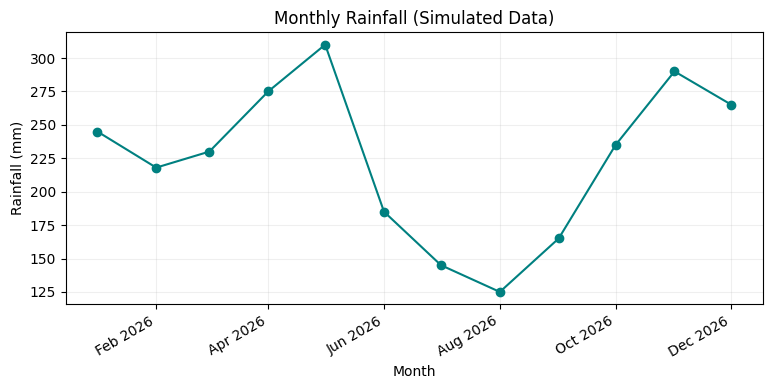

In [69]:
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(weather.index, weather["Rainfall_mm"], marker="o", color="teal")
ax.set(title="Monthly Rainfall (Simulated Data)", xlabel="Month", ylabel="Rainfall (mm)")

ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))

ax.grid(alpha=0.2)
fig.autofmt_xdate()
plt.show()

2.3 Selecting a Specific Time Period

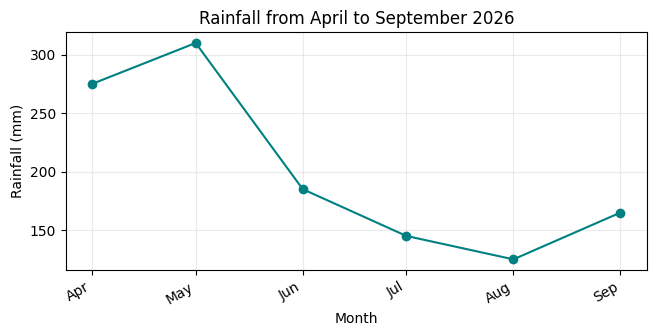

In [70]:
selected_period = weather.loc["2026-04":"2026-09"]

fig, ax = plt.subplots(figsize=(7.5, 3.5))
# disini letak selected period nya
ax.plot(selected_period.index, selected_period["Rainfall_mm"], marker="o", color="teal")
ax.set(title="Rainfall from April to September 2026", xlabel="Month", ylabel="Rainfall (mm)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.25)

fig.autofmt_xdate()
plt.show()

2.4 Comparing Time Series with Different Units

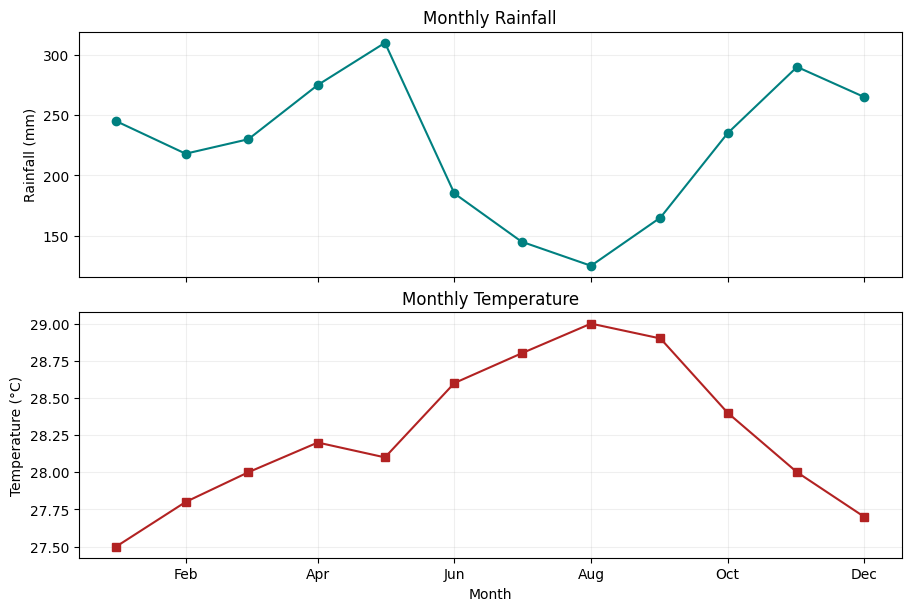

In [71]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True, layout="constrained")
axes[0].plot(weather.index, weather["Rainfall_mm"], marker="o", color="teal")
axes[0].set(title="Monthly Rainfall", ylabel="Rainfall (mm)")

axes[1].plot(weather.index, weather["Temperature_C"], marker="s", color="firebrick")
axes[1].set(title="Monthly Temperature", xlabel="Month", ylabel="Temperature (°C)")

axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b"))
for ax in axes:
    ax.grid(alpha=0.2)
plt.show()

2.5 Annotating Important Observations

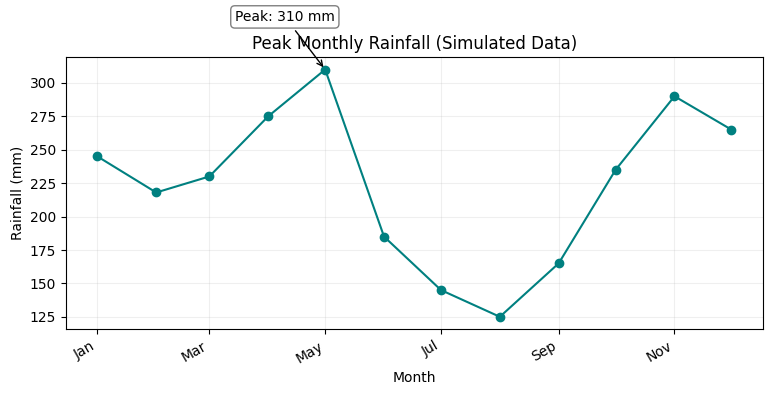

In [72]:
peak_date = weather["Rainfall_mm"].idxmax()
peak_value = weather["Rainfall_mm"].max()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(weather.index, weather["Rainfall_mm"], marker="o", color="teal")
ax.annotate(f"Peak: {peak_value} mm",
            xy=(peak_date, peak_value), xytext=(-65, 35),
            textcoords="offset points",
            arrowprops={"arrowstyle": "->", "color": "black"},
            bbox={"boxstyle": "round,pad=0.3", "fc": "white", "ec": "gray"})
ax.set(title="Peak Monthly Rainfall (Simulated Data)", xlabel="Month", ylabel="Rainfall (mm)")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax.grid(alpha=0.2)
fig.autofmt_xdate()
plt.show()

2.6 Using Twin Axes (Optional)

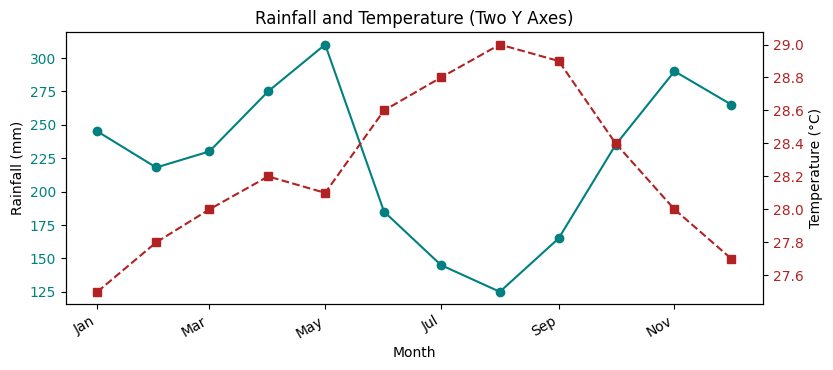

In [73]:
fig, ax1 = plt.subplots(figsize=(9, 4))

ax2 = ax1.twinx()

ax1.plot(weather.index, weather["Rainfall_mm"], color="teal", marker="o", label="Rainfall")
ax2.plot(weather.index, weather["Temperature_C"], color="firebrick", marker="s", linestyle="--", label="Temperature")

ax1.set(title="Rainfall and Temperature (Two Y Axes)", xlabel="Month", ylabel="Rainfall (mm)")
ax2.set_ylabel("Temperature (°C)")

ax1.tick_params(axis="y", labelcolor="teal")
ax2.tick_params(axis="y", labelcolor="firebrick")

ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
fig.autofmt_xdate()
plt.show()

3.1 Preparing Simulated Statistical Data

In [74]:
rng = np.random.default_rng(12)
scores_a = np.clip(rng.normal(loc=78, scale=8, size=40), 0, 100)
scores_b = np.clip(rng.normal(loc=72, scale=10, size=40), 0, 100)
print("Class A: n =", len(scores_a), ", mean =", round(scores_a.mean(), 2))
print("Class B: n =", len(scores_b), ", mean =", round(scores_b.mean(), 2))

Class A: n = 40 , mean = 77.99
Class B: n = 40 , mean = 72.93


3.2 Creating Bar Charts

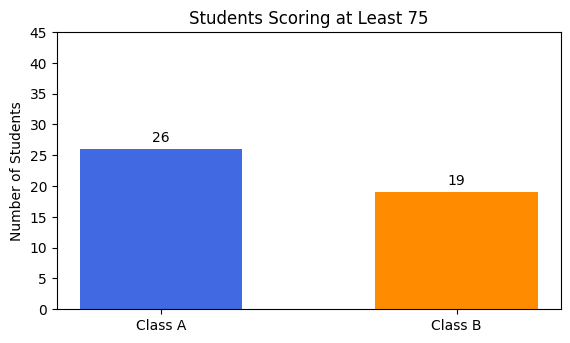

In [75]:
categories = ["Class A", "Class B"]
pass_counts = np.array([(scores_a >= 75).sum(), (scores_b >= 75).sum()])

fig, ax = plt.subplots(figsize=(6.5, 3.6))
bars = ax.bar(categories, pass_counts, color=["royalblue", "darkorange"], width=0.55)
ax.bar_label(bars, padding=3)
ax.set(title="Students Scoring at Least 75", ylabel="Number of Students")
ax.set_ylim(0, len(scores_a) + 5)
plt.show()

In [76]:
pass_counts

array([26, 19])


3.3 Creating Stacked Bar Charts

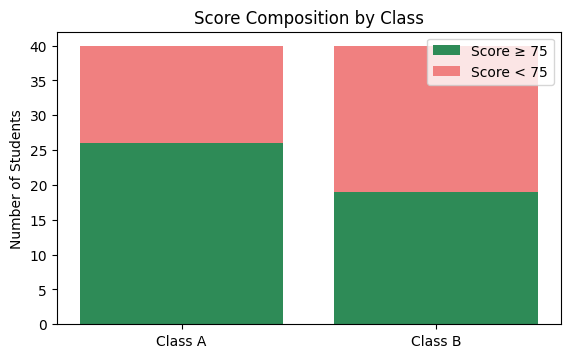

In [77]:
below_counts = np.array([(scores_a < 75).sum(), (scores_b < 75).sum()])

fig, ax = plt.subplots(figsize=(6.5, 3.8))

ax.bar(categories, pass_counts, label="Score ≥ 75", color="seagreen")
ax.bar(categories, below_counts, bottom=pass_counts, label="Score < 75", color="lightcoral")
ax.set(title="Score Composition by Class", ylabel="Number of Students")

ax.legend()
plt.show()

In [78]:
below_counts

array([14, 21])

3.4 Understanding Histograms

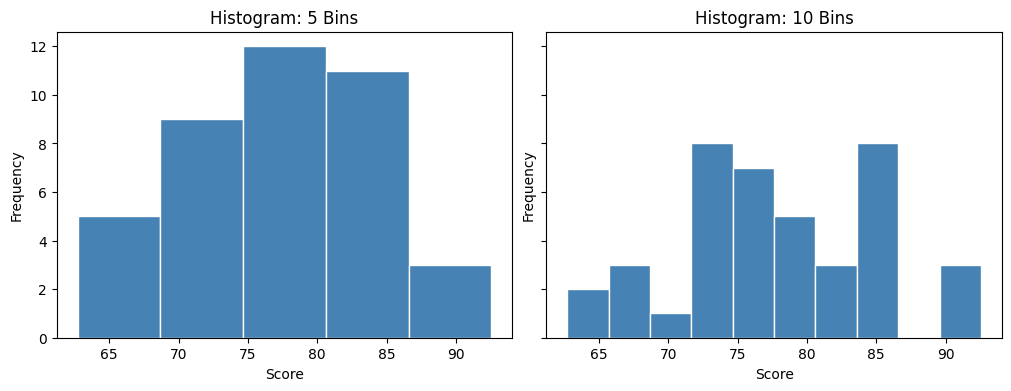

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, layout="constrained")
for ax, n_bins in zip(axes, [5, 10]):
    ax.hist(scores_a, bins=n_bins, color="steelblue", edgecolor="white")
    ax.set(title=f"Histogram: {n_bins} Bins", xlabel="Score", ylabel="Frequency")
plt.show()

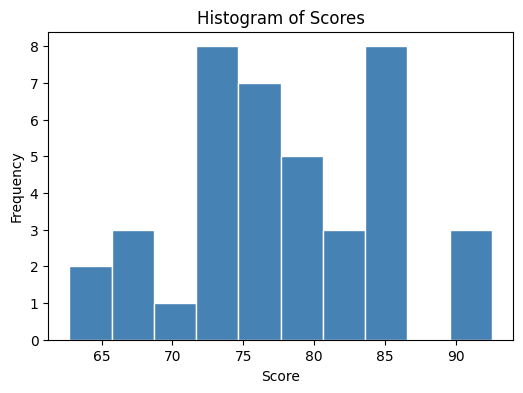

In [80]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.hist(
    scores_a,
    bins=10,
    color="steelblue",
    edgecolor="white"
)
ax.set(
    title="Histogram of Scores",
    xlabel="Score",
    ylabel="Frequency"
)
plt.show()

3.5 Comparing Distributions with Boxplots

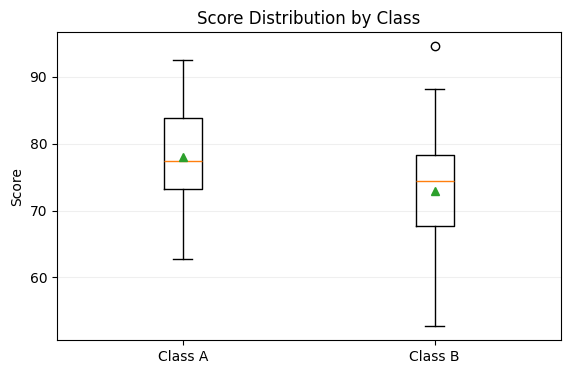

In [81]:
fig, ax = plt.subplots(figsize=(6.5, 4))
# segitiga adalah means jika showmeans true
ax.boxplot([scores_a, scores_b], showmeans=True)
ax.set_xticks([1, 2], categories)
ax.set(title="Score Distribution by Class", ylabel="Score")
ax.grid(axis="y", alpha=0.2)
plt.show()

3.6 Exploring Relationships with Scatter Plots

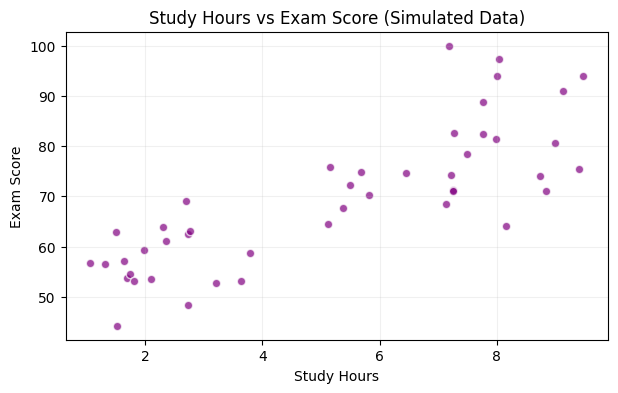

Pearson correlation: 0.81


In [82]:
# buat data baru
study_hours = rng.uniform(1, 10, size=45)
exam_scores = np.clip(48 + 4.3 * study_hours + rng.normal(0, 9, size=45), 0, 100)

fig, ax = plt.subplots(figsize=(7, 4))

ax.scatter(study_hours, exam_scores, color="purple", alpha=0.7, edgecolors="white")
ax.set(title="Study Hours vs Exam Score (Simulated Data)", xlabel="Study Hours", ylabel="Exam Score")
ax.grid(alpha=0.18)

plt.show()
print("Pearson correlation:", round(np.corrcoef(study_hours, exam_scores)[0, 1], 3))

4.1 Choosing a Plot Style

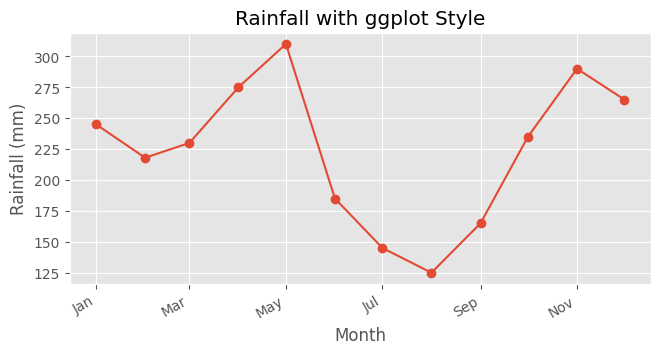

In [83]:
with plt.style.context("ggplot"):
    fig, ax = plt.subplots(figsize=(7.5, 3.7))
    ax.plot(weather.index, weather["Rainfall_mm"], marker="o")
    ax.set(title="Rainfall with ggplot Style", xlabel="Month", ylabel="Rainfall (mm)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    fig.autofmt_xdate()
    plt.show()

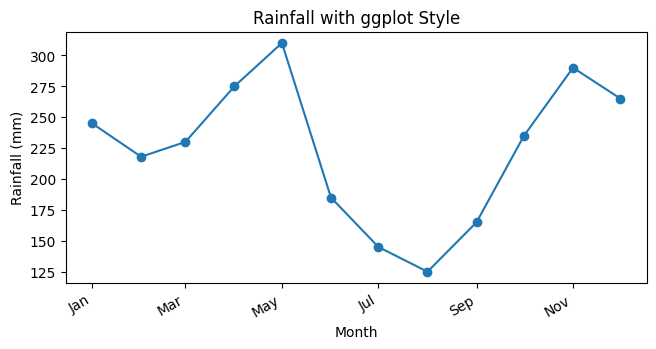

In [84]:
    fig, ax = plt.subplots(figsize=(7.5, 3.7))
    ax.plot(weather.index, weather["Rainfall_mm"], marker="o")
    ax.set(title="Rainfall with ggplot Style", xlabel="Month", ylabel="Rainfall (mm)")
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
    fig.autofmt_xdate()
    plt.show()

4.2 Saving PNG, PDF, and SVG Files

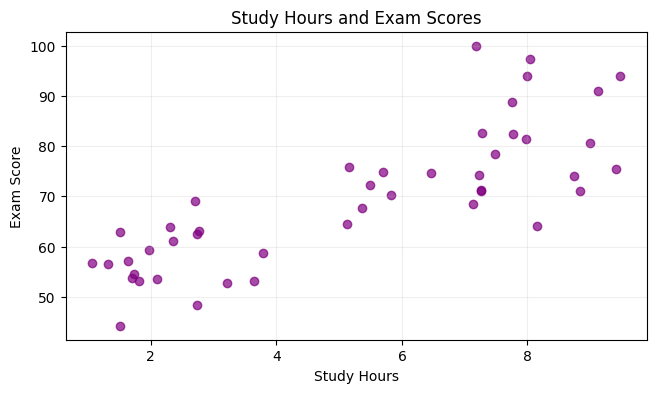

Saved to: /content/week12_figures


In [85]:
output_dir = Path("week12_figures")
output_dir.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(7.5, 4))
ax.scatter(study_hours, exam_scores, alpha=0.7, color="purple")
ax.set(title="Study Hours and Exam Scores", xlabel="Study Hours", ylabel="Exam Score")
ax.grid(alpha=0.2)

fig.savefig(output_dir / "week12_scatter.png", dpi=300, bbox_inches="tight")
fig.savefig(output_dir / "week12_scatter.pdf", bbox_inches="tight")
fig.savefig(output_dir / "week12_scatter.svg", bbox_inches="tight")
plt.show()
print("Saved to:", output_dir.resolve())

4.3 Adjusting Figure Size and Resolution

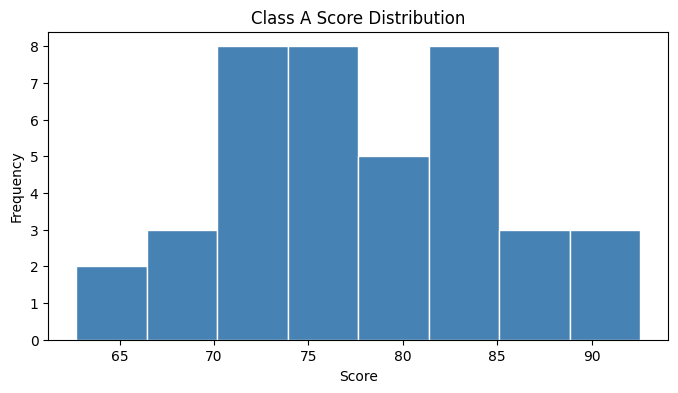

File: week12_figures/week12_histogram_300dpi.png
File size: 53.2 KB


In [86]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(scores_a, bins=8, edgecolor="white", color="steelblue")
ax.set(title="Class A Score Distribution", xlabel="Score", ylabel="Frequency")
file_path = output_dir / "week12_histogram_300dpi.png"
fig.savefig(file_path, dpi=300, bbox_inches="tight")
plt.show()
print("File:", file_path)
print("File size:", round(file_path.stat().st_size / 1024, 1), "KB")


4.4 Checking Saved Files

In [87]:
for name in ["week12_scatter.png", "week12_scatter.pdf", "week12_scatter.svg",
             "week12_histogram_300dpi.png"]:
    path = output_dir / name
    print(f"{name}: {'Found' if path.exists() else 'Missing'}")

week12_scatter.png: Found
week12_scatter.pdf: Found
week12_scatter.svg: Found
week12_histogram_300dpi.png: Found


5. Independent Student Exercises

Exercise 1 — Basic Line Plot

1. Buat grafik garis dengan fig, ax = plt.subplots() dan ax.plot().
2. Tambahkan marker bulat, judul, serta label sumbu X dan Y dalam bahasa Inggris.
3. Sebutkan minggu dengan jumlah pengunjung tertinggi.

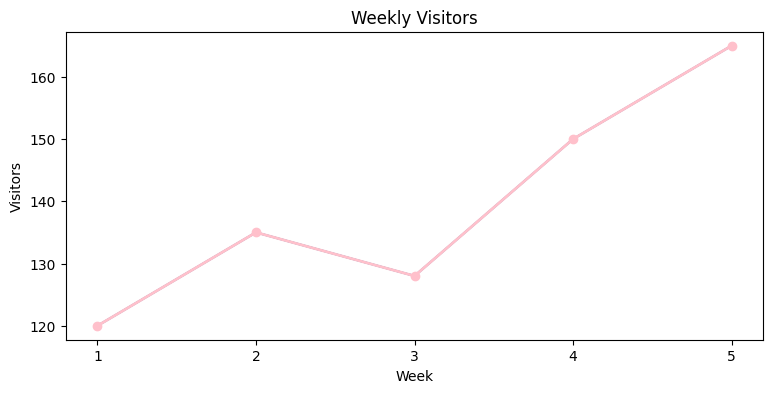


Minggu dengan jumlah pengunjung tertinggi adalah minggu ke-5


In [99]:
weeks = [1, 2, 3, 4, 5]
visitors = [120, 135, 128, 150, 165]

# 1.Buat grafik garis dengan fig, ax = plt.subplots() dan ax.plot().
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(weeks, visitors)

# 2.Tambahkan marker bulat, judul, serta label sumbu X dan Y dalam bahasa Inggris.
ax.plot(weeks, visitors, color="pink", marker="o", linewidth=2)
ax.set_title("Weekly Visitors")
ax.set_xlabel("Week")
ax.set_ylabel("Visitors")
ax.set_xticks(weeks)
plt.show()
print()

#3.Sebutkan minggu dengan jumlah pengunjung tertinggi
minggu_tertinggi = weeks[visitors.index(max(visitors))]
print(f"Minggu dengan jumlah pengunjung tertinggi adalah minggu ke-{minggu_tertinggi}")


Exercise 2 — Comparing Two Time Series

1. Buat dua garis dalam satu grafik dengan warna, label, dan legend berbeda.
2. Atur label tanggal supaya mudah dibaca.
3. Identifikasi bulan ketika kedua stasiun memiliki selisih terbesar.

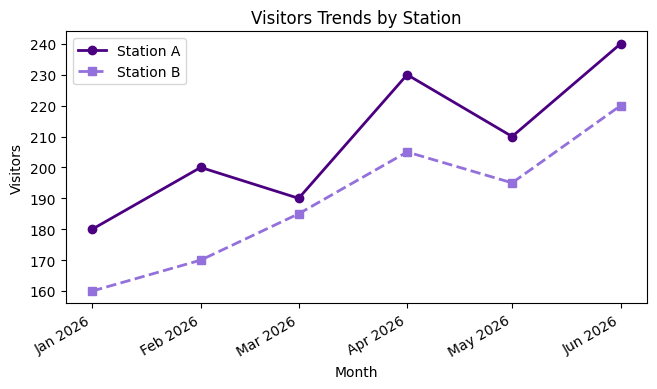


Selisih per bulan: [20 30  5 25 15 20]
Selisih terbesar: 30 pengunjung pada February 2026


In [89]:
dates = pd.date_range("2026-01-01", periods=6, freq="MS")
station_a = [180, 200, 190, 230, 210, 240]
station_b = [160, 170, 185, 205, 195, 220]


fig, ax = plt.subplots(figsize=(7.5, 4))
ax.plot(dates, station_a, color="indigo", marker="o", linewidth=2, label="Station A")
ax.plot(dates, station_b, color="mediumpurple", marker="s", linestyle="--", linewidth=2, label="Station B")
ax.set(title="Visitors Trends by Station", xlabel="Month", ylabel="Visitors")
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
fig.autofmt_xdate()
ax.set_xticks(dates)
ax.legend()
plt.show()
print()

# Selisih terbesar antara kedua stasiun
selisih = np.abs(np.array(station_a) - np.array(station_b))
bulan_terbesar = dates[selisih.argmax()]
print("Selisih per bulan:", selisih)
print(f"Selisih terbesar: {selisih.max()} pengunjung pada {bulan_terbesar.strftime('%B %Y')}")


Exercise 3 — Bar Charts and Stacked Bars

1. Buat bar chart yang memperlihatkan jumlah completed.
2. Buat stacked bar chart menggunakan bottom=completed.
3. Beri judul, label sumbu, dan legenda yang jelas.

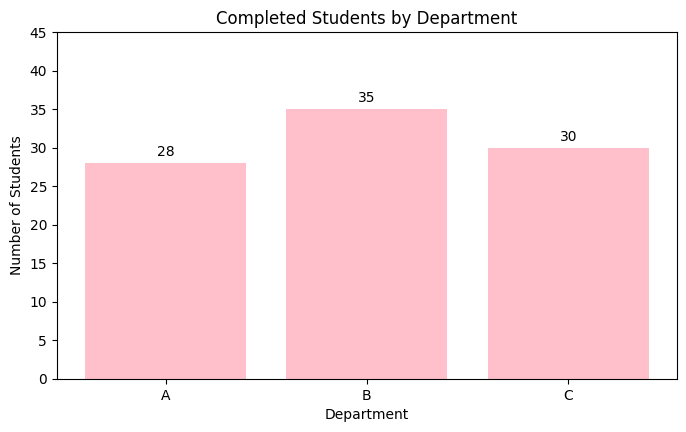

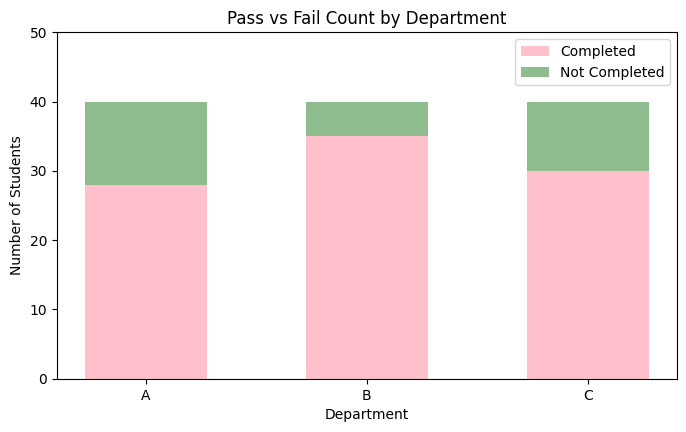

In [98]:
departments = ["A", "B", "C"]
completed = np.array([28, 35, 30])
not_completed = np.array([12, 5, 10])

# Buat bar chart yang memperlihatkan jumlah completed
fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(departments, completed, label = "Completed", color = "pink")
ax.bar_label(bars, padding=3)
ax.set(title="Completed Students by Department", xlabel="Department", ylabel="Number of Students")
ax.set_ylim(0, 45)
plt.show()

# Buat stacked bar chart menggunakan bottom=completed
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(departments, completed, label="Completed", color="pink", width=0.55)
ax.bar(departments, not_completed, bottom=completed, label="Not Completed", color="darkseagreen", width=0.55)
ax.set(title="Pass vs Fail Count by Department", xlabel="Department", ylabel="Number of Students")
ax.set_ylim(0, 50)
ax.legend(loc="upper right")
plt.show()


Exercise 4 — Histogram and Boxplot

1. Buat histogram scores_a dengan bins=6 dan bins=12.
2. Bandingkan bentuk histogram keduanya dalam satu kalimat.
3. Buat boxplot dua kelas dan bandingkan median secara visual.

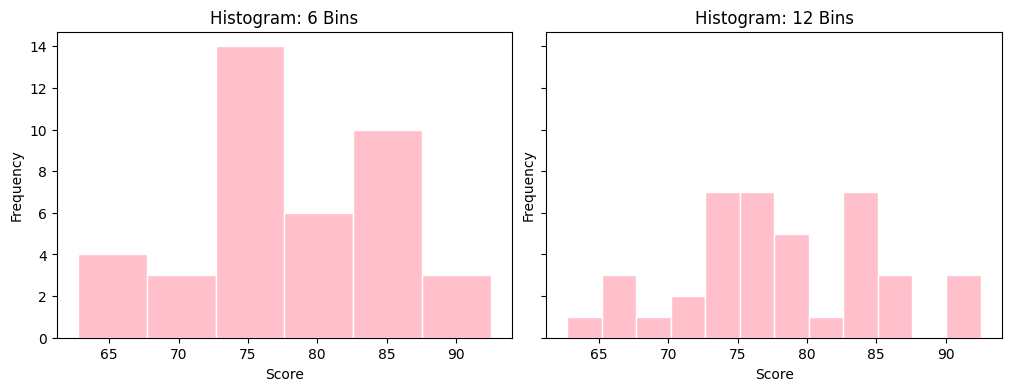


Histogram 6 bins lebih sederhana, sedangkan 12 bins menampilkan distribusi frekuensi lebih rinci.



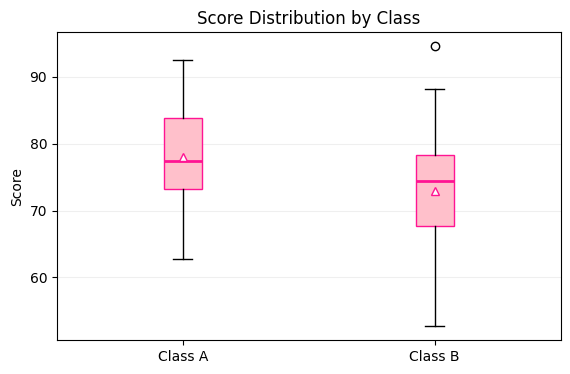


Garis median Class A lebih tinggi daripada Class B, jadi secara umum nilai Class A sedikit lebih tinggi.
Median Class A: 77.34
Median Class B: 74.34


In [100]:
# Buat histogram scores_a dengan bins=6 dan bins=12
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True, layout="constrained")
for ax, n_bins in zip(axes, [6, 12]):
    ax.hist(scores_a, bins=n_bins, color="pink", edgecolor="white")
    ax.set(title=f"Histogram: {n_bins} Bins", xlabel="Score", ylabel="Frequency")
plt.show()
print()

# Bandingkan bentuk histogram keduanya dalam satu kalimat
print("Histogram 6 bins lebih sederhana, sedangkan 12 bins menampilkan distribusi frekuensi lebih rinci.")
print()

# Buat boxplot dua kelas dan bandingkan median secara visual
fig, ax = plt.subplots(figsize=(6.5, 4))
ax.boxplot([scores_a, scores_b], showmeans=True, patch_artist=True, boxprops=dict(facecolor="pink", edgecolor="deeppink"), medianprops=dict(color="deeppink", linewidth=2), meanprops=dict(marker="^", markerfacecolor="white", markeredgecolor="deeppink"), )
ax.set_xticks([1, 2], categories)
ax.set(title="Score Distribution by Class", ylabel="Score")
ax.grid(axis="y", alpha=0.2)
plt.show()
print()

print("Garis median Class A lebih tinggi daripada Class B, jadi secara umum nilai Class A sedikit lebih tinggi.")
print("Median Class A:", round(np.median(scores_a), 2))
print("Median Class B:", round(np.median(scores_b), 2))


Exercise 5 — Scatter Plot

1. Buat scatter plot antara jam belajar dan nilai ujian.
2. Jelaskan apakah arah hubungan terlihat positif, negatif, atau tidak jelas.

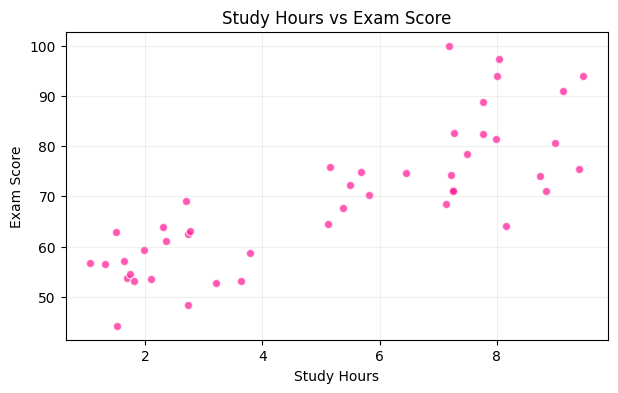


Pearson correlation: 0.81
Arah hubungan terlihat positif, karena semakin lama waktu belajar (study hours), nilai ujian (exam score) cenderung semakin tinggi.


In [92]:
# Buat scatter plot antara jam belajar dan nilai ujian
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(study_hours, exam_scores, color="deeppink", alpha=0.7, edgecolors="white")
ax.set(title="Study Hours vs Exam Score", xlabel="Study Hours", ylabel="Exam Score")
ax.grid(alpha=0.18)
plt.show()
print()

# Jelaskan apakah arah hubungan terlihat positif, negatif, atau tidak jelas
print("Pearson correlation:", round(np.corrcoef(study_hours, exam_scores)[0, 1], 3))
print("Arah hubungan terlihat positif, karena semakin lama waktu belajar (study hours), nilai ujian (exam score) cenderung semakin tinggi.")

Exercise 6 — Saving a Publication-Ready Figure

1. Pilih salah satu grafik yang sudah dibuat.
2. Atur ukuran figsize=(8, 4) dan tambahkan judul serta label yang sesuai.
3. Simpan sebagai PNG (300 dpi) dan PDF dengan bbox_inches="tight".
4. Pastikan kedua file berhasil dibuat dan jelaskan perbedaan kegunaannya.

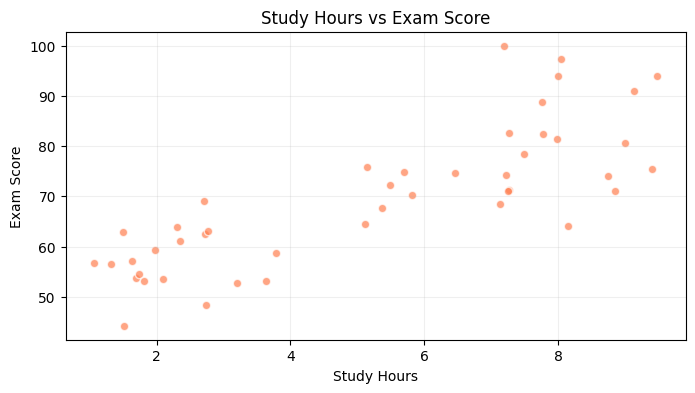


week12_scatter.png: Found
week12_scatter.pdf: Found
Perbedaannya adalah PNG untuk menyimpan grafik sebagai gambar, sedangkan PDF untuk publikasi dan pencetakan dengan kualitas tetap tajam saat diperbesar.


In [93]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.scatter(study_hours, exam_scores, color="coral", alpha=0.7, edgecolors="white")
ax.set(title="Study Hours vs Exam Score", xlabel="Study Hours", ylabel="Exam Score")
ax.grid(alpha=0.2)

fig.savefig(output_dir / "week12_scatter.png", dpi=300, bbox_inches="tight")
fig.savefig(output_dir / "week12_scatter.pdf", bbox_inches="tight")
plt.show()
print()

for name in ["week12_scatter.png", "week12_scatter.pdf"]:
    path = output_dir / name
    print(f"{name}: {'Found' if path.exists() else 'Missing'}")

print("Perbedaannya adalah PNG untuk menyimpan grafik sebagai gambar, sedangkan PDF untuk publikasi dan pencetakan dengan kualitas tetap tajam saat diperbesar.")